In [17]:
# import necessary packages
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [18]:
import pickle
from pathlib import Path

# this allows you to recall the dictionary that contains all the temporal networks and use it in this notebook
save_path = Path("../Data/Cleaned/temporal_networks.pkl")
with save_path.open("rb") as file:
    networks_by_time = pickle.load(file) #the dictionary is called "networks_by_time"

parameters

In [24]:
BETA = 0.02
DT = 24 * 3600
N_REPS = 100
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5]
rng = np.random.default_rng(42)

student list and arrays (used by the simulation later)

In [20]:
# students = everyone who appears in at least one snapshot
ids = np.array(sorted(set().union(*[set(G.nodes) for G in networks_by_time.values()])))
N = len(ids)

# flatten the snapshots into time-ordered arrays of contacts
ts = np.array(sorted(networks_by_time))               # unique time stamps, in order
t_list, i_list, j_list = [], [], []
for t in ts:
    for u, v in networks_by_time[t].edges():
        t_list.append(t); i_list.append(u); j_list.append(v)

t_arr = np.array(t_list)
i_arr = np.searchsorted(ids, i_list)                   # student ID -> 0..N-1
j_arr = np.searchsorted(ids, j_list)
bounds = np.append(np.searchsorted(t_arr, ts), len(t_arr))   # contacts at ts[k] are rows bounds[k]:bounds[k+1]

print("students:", N, "| time stamps:", len(ts), "| contacts:", len(t_arr))

students: 327 | time stamps: 7375 | contacts: 188508


temporal degree

In [21]:
# total contacts per student across all snapshots, divided by the number of time stamps
degree_sum = np.zeros(N)         #running total per student
for G in networks_by_time.values():        #each snapshot
    for student, d in G.degree():       # student's contacts at that time stamp
        degree_sum[np.searchsorted(ids, student)] += d        # add to their total
temporal_degree = degree_sum / len(networks_by_time)         # average contacts per time stamp

# check: the array method should give the same answer, so this should print True
deg = np.bincount(i_arr, minlength=N) + np.bincount(j_arr, minlength=N)      # count contacts via arrays
print(np.allclose(temporal_degree, deg / len(ts)))

# top 5 students by temporal degree
top = np.argsort(-temporal_degree)[:5]
for rank, k in enumerate(top, start=1):
    print(f"{rank}. student {ids[k]}: {temporal_degree[k]:.3f}")

import polars as pl
degree_table = pl.DataFrame({"student": ids, "temporal_degree": temporal_degree}).sort("temporal_degree", descending=True)
print(degree_table)             # all 327, highest first
print(degree_table.describe())  # min, max, mean, median

True
1. student 884: 0.630
2. student 1359: 0.588
3. student 513: 0.574
4. student 255: 0.561
5. student 122: 0.556
shape: (327, 2)
┌─────────┬─────────────────┐
│ student ┆ temporal_degree │
│ ---     ┆ ---             │
│ i64     ┆ f64             │
╞═════════╪═════════════════╡
│ 884     ┆ 0.630102        │
│ 1359    ┆ 0.588203        │
│ 513     ┆ 0.573695        │
│ 255     ┆ 0.560814        │
│ 122     ┆ 0.556339        │
│ …       ┆ …               │
│ 103     ┆ 0.005831        │
│ 165     ┆ 0.004475        │
│ 681     ┆ 0.003661        │
│ 62      ┆ 0.00122         │
│ 434     ┆ 0.000949        │
└─────────┴─────────────────┘
shape: (9, 3)
┌────────────┬────────────┬─────────────────┐
│ statistic  ┆ student    ┆ temporal_degree │
│ ---        ┆ ---        ┆ ---             │
│ str        ┆ f64        ┆ f64             │
╞════════════╪════════════╪═════════════════╡
│ count      ┆ 327.0      ┆ 327.0           │
│ null_count ┆ 0.0        ┆ 0.0             │
│ mean       ┆ 549.036

SIR Function

In [22]:
def sir(immune, seed, k0, beta, dt, rng, horizon=np.inf):
    """One outbreak. immune = student indices; seed = student index; k0 = start time-stamp index;
    horizon = max seconds the outbreak may run (inf = no limit). Returns # students infected (seed included)."""
    inf = np.full(N, np.inf)          # infection time per student (inf = never infected)
    blocked = np.zeros(N, bool)         # True = immunized
    blocked[np.asarray(immune, dtype=int)] = True   # mark immunized students
    inf[seed] = ts[k0] - 20           # seed infected one step before start (can spread immediately)
    last = ts[k0]               # time of most recent infection
    for k in range(k0, len(ts)):         # replay time stamps in order
        t = ts[k]                  # current time
        if t - last > dt or t - ts[k0] > horizon:   # nobody infectious (>24 h) OR time limit reached
            break                    # outbreak over
        a = i_arr[bounds[k]:bounds[k+1]]      # student 1 of each contact now
        b = j_arr[bounds[k]:bounds[k+1]]      # student 2 of each contact now
        new = []                  # newly infected this step
        for u, v in ((a, b), (b, a)):         # check both directions
            can_pass = (inf[u] < t) & (t - inf[u] <= dt)       # u infectious (infected, <24 h ago)
            can_catch = np.isinf(inf[v]) & ~blocked[v]         # v susceptible (never infected, not immune)
            hit = can_pass & can_catch & (rng.random(len(u)) < beta)   # roll the transmission chance
            new.append(v[hit])                # save who got infected
        new = np.unique(np.concatenate(new))  # combine, remove repeats
        if len(new):           # anyone newly infected?
            inf[new] = t              # record infection time (after loop: no chaining in one step)
            last = t           # update last infection time
    return int(np.isfinite(inf).sum())     # count of infected students

In [23]:
DAY1_END = np.searchsorted(ts, ts[0] + 24*3600)   # index where day 1 ends (seeds start in day 1)

def draw_start_and_seed(immune, rng):
    while True:                               # retry until valid
        k0 = rng.integers(0, DAY1_END)        # random start time on day 1
        present = np.unique(np.r_[i_arr[bounds[k0]:bounds[k0+1]], j_arr[bounds[k0]:bounds[k0+1]]])   # students in contact now
        candidates = np.setdiff1d(present, immune)   # remove immunized students
        if len(candidates):                   # anyone left?
            return k0, rng.choice(candidates) # random seed from them

reachability and check

In [25]:
ev_k = np.repeat(np.arange(len(ts)), np.diff(bounds))   # time-stamp index of each contact row

def compute_reachability(horizon, n_starts, rng):
    score = np.zeros(N)                   # one score per student
    for n in range(N):                   # every student
        rows_n = np.where((i_arr == n) | (j_arr == n))[0]   # contact rows involving student n
        starts = np.unique(ev_k[rows_n])         # time stamps where they have a contact
        starts = starts[starts < DAY1_END]              # day 1 only
        if len(starts) == 0:                 # no contact on day 1: score stays 0
            continue
        chosen = rng.choice(starts, min(n_starts, len(starts)), replace=False)   # random start times
        score[n] = np.mean([sir([], n, k, 1.0, DT, rng, horizon=horizon) - 1 for k in chosen])   # avg # reached (beta = 1)
    return score

scans horizons so we can pick value 

In [26]:
scan = {}                                               # horizon (hours) -> scores
for hours in [0.5, 1, 2, 4, 8]:                         # horizons to try
    r = compute_reachability(hours * 3600, 2, rng)      # 2 start times per student keeps it quick
    scan[hours] = r                                     # save scores
    print(f"{hours} h: min/median/max = {r.min():.0f} / {np.median(r):.0f} / {r.max():.0f}, "
          f"distinct = {len(np.unique(r.round(1)))}")   # spread of scores (want wide spread, many distinct)

0.5 h: min/median/max = 0 / 20 / 218, distinct = 149
1 h: min/median/max = 0 / 46 / 254, distinct = 189
2 h: min/median/max = 0 / 128 / 284, distinct = 239
4 h: min/median/max = 0 / 214 / 305, distinct = 223
8 h: min/median/max = 0 / 225 / 310, distinct = 188


final reachability scores using horizon value chosen

In [27]:
HORIZON_HOURS = 2                     # horizon chose from the scan
reachability = compute_reachability(HORIZON_HOURS * 3600, 5, rng)   # 5 start times averaged per student
print("min / median / max:", reachability.min(), np.median(reachability), reachability.max())

min / median / max: 0.0 134.8 276.8


Run SIR simulation
- create baseline with no immunizations
- random immunization vs. targeted
- each immunization strategy is tested at different levels of coverage
- each strat + coverage pair is ran 100 times 
- take average end outbreak size from he 100 simulations and convert to percentage

In [28]:
#baseline -- no immunization
baseline = []                                 # epidemic size from each run
for _ in range(N_REPS):                       # 100 runs
    k0, s = draw_start_and_seed([], rng)      # random day-1 start time + seed (nobody immune)
    baseline.append(sir([], s, k0, BETA, DT, rng))   # run outbreak, save # infected
print("baseline mean share infected:", round(np.mean(baseline) / N, 2))   # avg outbreak / 327

# experiment (random vs. temporal degree vs. reachability)
def top_k(scores, k, rng):
    perm = rng.permutation(N)                 # shuffle students (random tie-breaking)
    return perm[np.argsort(-scores[perm], kind="stable")][:k]   # sort high to low, keep first k

scores = {"temporal_degree": temporal_degree, "reachability": reachability}   # score per targeted strategy
strategies = ["random", "temporal_degree", "reachability"]                    # all strategies

rows = []                                     # one row per simulation
for cov in COVERAGES:                         # 10% ... 50%
    k = int(round(cov * N))                   # number of students to immunize
    for strat in strategies:                  # each strategy
        for rep in range(N_REPS):             # 100 runs each
            if strat == "random":
                immune = rng.choice(N, k, replace=False)    # new random set each run
            else:
                immune = top_k(scores[strat], k, rng)       # top-k by that strategy's score
            k0, s = draw_start_and_seed(immune, rng)        # start time + seed (not immune)
            rows.append((strat, cov, rep, sir(immune, s, k0, BETA, DT, rng)))   # save outbreak size

results = pl.DataFrame(rows, schema=["strategy", "coverage", "rep", "size"], orient="row")   # all runs in a table

summary = (results.group_by(["strategy", "coverage"])   # one group per strategy + coverage
           .agg(mean=pl.col("size").mean(), sd=pl.col("size").std())   # avg and spread of outbreak size
           .sort(["strategy", "coverage"]))       # tidy order
print(summary)


baseline mean share infected: 0.45
shape: (15, 4)
┌─────────────────┬──────────┬────────┬───────────┐
│ strategy        ┆ coverage ┆ mean   ┆ sd        │
│ ---             ┆ ---      ┆ ---    ┆ ---       │
│ str             ┆ f64      ┆ f64    ┆ f64       │
╞═════════════════╪══════════╪════════╪═══════════╡
│ random          ┆ 0.1      ┆ 106.61 ┆ 56.26361  │
│ random          ┆ 0.2      ┆ 63.15  ┆ 41.14335  │
│ random          ┆ 0.3      ┆ 42.16  ┆ 32.227637 │
│ random          ┆ 0.4      ┆ 23.44  ┆ 17.725927 │
│ random          ┆ 0.5      ┆ 14.68  ┆ 12.220103 │
│ …               ┆ …        ┆ …      ┆ …         │
│ temporal_degree ┆ 0.1      ┆ 56.44  ┆ 42.172402 │
│ temporal_degree ┆ 0.2      ┆ 27.93  ┆ 25.244363 │
│ temporal_degree ┆ 0.3      ┆ 9.69   ┆ 10.902409 │
│ temporal_degree ┆ 0.4      ┆ 4.63   ┆ 4.9332    │
│ temporal_degree ┆ 0.5      ┆ 2.77   ┆ 2.313138  │
└─────────────────┴──────────┴────────┴───────────┘


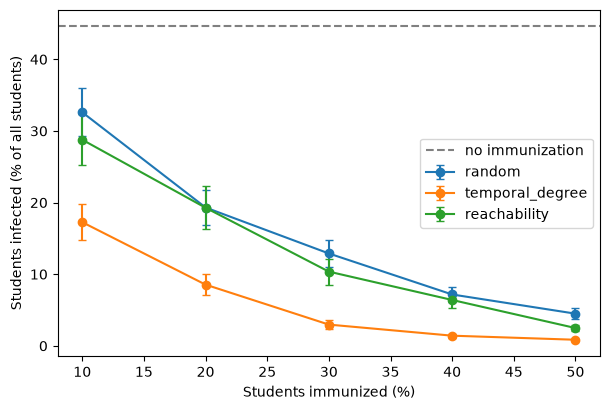

In [29]:
#  plot (error bars = 95% CI of the mean) 
plt.figure(figsize=(7, 4.5))                  # figure size
for strat in strategies:                      # one line per strategy
    s = summary.filter(pl.col("strategy") == strat)   # this strategy's rows
    plt.errorbar(s["coverage"].to_numpy() * 100,      # x: coverage as %
                 s["mean"].to_numpy() / N * 100,      # y: mean infected as % of students
                 yerr=1.96 * s["sd"].to_numpy() / np.sqrt(N_REPS) / N * 100,   # error bars: 95% CI of the mean
                 marker="o", capsize=3, label=strat)  # dots, bar caps, legend label
plt.axhline(np.mean(baseline) / N * 100, ls="--", color="gray", label="no immunization")   # baseline line
plt.xlabel("Students immunized (%)")          # x-axis label
plt.ylabel("Students infected (% of all students)")   # y-axis label
plt.legend()                                  # show legend
plt.show()                                    # draw plot